# Training a non-linear model (decision tree and random forest)

### Load imports

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
)
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    precision_score,
    accuracy_score,
    f1_score
)
import seaborn
from sklearn.exceptions import UndefinedMetricWarning
from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

### Split dataset into training and testing sets

In [2]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

## Main analysis (decision tree)

### Create a decision tree model and tune hyperparameter

In [3]:
# Initialize decision tree model
dt = DecisionTreeClassifier(class_weight="balanced", random_state=123)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid_dt = {
    "max_depth": [3, 5, 7, 10, 20, 50, None],
    "criterion": ["gini", "entropy"],
}

scoring = ["accuracy", "precision", "recall", "f1"]

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
dt_grid_search = GridSearchCV(
    dt,
    param_grid=param_grid_dt,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
dt_grid_search.fit(X_train, y_train)

print(
    f"We evaluated 7 maximum depth values and 2 criteria across 5 cross-validation folds, totaling 70 experimental fits. Using recall as our metric, the best hyperparameters were {dt_grid_search.best_params_}, which achieved a score of {dt_grid_search.best_score_:.2f}."
)

We evaluated 7 maximum depth values and 2 criteria across 5 cross-validation folds, totaling 70 experimental fits. Using recall as our metric, the best hyperparameters were {'criterion': 'entropy', 'max_depth': 5}, which achieved a score of 0.70.


### Display results

param_max_depth param_criterion  mean_test_accuracy  rank_test_accuracy  mean_test_precision  rank_test_precision  mean_test_recall  rank_test_recall  mean_test_f1  rank_test_f1
              3            gini                0.55                  13                 0.28                   13              0.69                 3          0.40             5
              5            gini                0.56                  12                 0.29                   12              0.70                 2          0.41             2
              7            gini                0.58                   9                 0.29                    9              0.66                 6          0.41             3
             10            gini                0.60                   7                 0.30                    8              0.61                 8          0.40             8
             20            gini                0.64                   5                 0.31                  

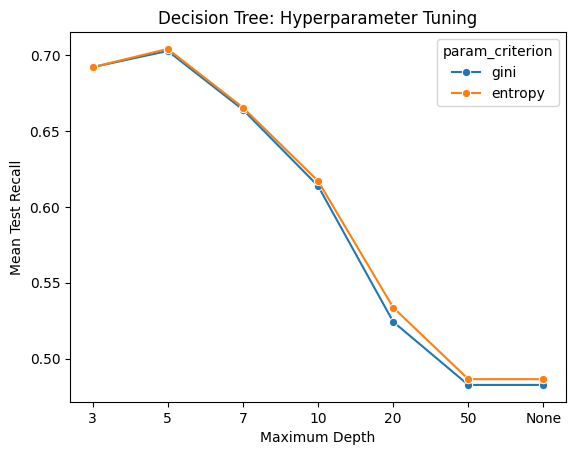

In [4]:
# Print results
dt_grid_search_results = pd.DataFrame(dt_grid_search.cv_results_)

dt_results_table = dt_grid_search_results[
    [
        "param_max_depth",
        "param_criterion",
        "mean_test_accuracy",
        "rank_test_accuracy",
        "mean_test_precision",
        "rank_test_precision",
        "mean_test_recall",
        "rank_test_recall",
        "mean_test_f1",
        "rank_test_f1",
    ]
].copy()

print(dt_results_table.to_string(index=False, float_format="%.2f"))

# Plot results by hyperparameter
dt_results_plot = dt_grid_search_results.copy()
dt_results_plot["param_max_depth"] = (
    dt_results_plot["param_max_depth"].fillna("None").astype(str)
)

depth_order = ["3", "5", "7", "10", "20", "50", "None"]

plt.figure()
seaborn.lineplot(
    data=dt_results_plot,
    x="param_max_depth",
    y="mean_test_recall",
    hue="param_criterion",
    marker="o",
    sort=False,
    hue_order=["gini", "entropy"],
)

plt.xticks(ticks=range(len(depth_order)), labels=depth_order)

plt.title("Decision Tree: Hyperparameter Tuning")
plt.xlabel("Maximum Depth")
plt.ylabel("Mean Test Recall")
plt.show()

### Interpret model

Using the tuned hyperparameters, the feature importance (based on impurity reduction) for each feature is:

STOP_WAS_INITIATED_based on self initiated                                 0.503136
STOP_LOCATION_PATROL_BORO_NAME_pbbx                                        0.177044
STOP_LOCATION_PATROL_BORO_NAME_pbms                                        0.125394
SUSPECTED_CRIME_DESCRIPTION_cpw                                            0.052444
SUSPECT_REPORTED_AGE_<18                                                   0.025963
SUSPECTED_CRIME_DESCRIPTION_assault                                        0.016293
SUSPECT_REPORTED_AGE_25–44                                                 0.016266
SUSPECTED_CRIME_DESCRIPTION_cpsp                                           0.016092
STOP_LOCATION_PATROL_BORO_NAME_pbmn                                        0.013490
STOP_LOCATION_PATROL_BORO_NAME_pbbs                                        0.013424
SUSPECT_REPORTED_AGE_18–24                          

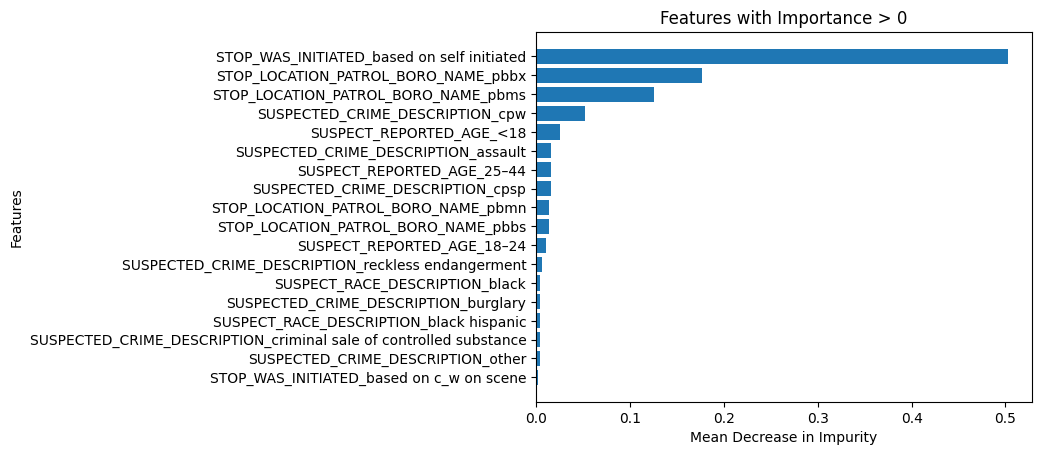

|--- STOP_WAS_INITIATED_based on self initiated <= 0.50
|   |--- STOP_LOCATION_PATROL_BORO_NAME_pbms <= 0.50
|   |   |--- SUSPECTED_CRIME_DESCRIPTION_cpw <= 0.50
|   |   |   |--- STOP_LOCATION_PATROL_BORO_NAME_pbmn <= 0.50
|   |   |   |   |--- SUSPECT_REPORTED_AGE_25–44 <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- SUSPECT_REPORTED_AGE_25–44 >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- STOP_LOCATION_PATROL_BORO_NAME_pbmn >  0.50
|   |   |   |   |--- SUSPECTED_CRIME_DESCRIPTION_other <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- SUSPECTED_CRIME_DESCRIPTION_other >  0.50
|   |   |   |   |   |--- class: 0
|   |   |--- SUSPECTED_CRIME_DESCRIPTION_cpw >  0.50
|   |   |   |--- STOP_LOCATION_PATROL_BORO_NAME_pbbx <= 0.50
|   |   |   |   |--- SUSPECT_REPORTED_AGE_18–24 <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- SUSPECT_REPORTED_AGE_18–24 >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- STOP_LOCATION_PATROL_BORO_NAME_

In [5]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_dt_model = dt_grid_search.best_estimator_

# Extract the feature importances from the best model
dt_importances = best_dt_model.feature_importances_
dt_feature_importances = pd.Series(dt_importances, index=X_train.columns)

print(
    "Using the tuned hyperparameters, the feature importance (based on impurity reduction) for each feature is:"
)
print()
print(dt_feature_importances.sort_values(ascending=False))

# Plot features that have positive values
dt_plot_df = dt_feature_importances[dt_feature_importances > 0].sort_values(
    ascending=True
)

plt.figure()
plt.barh(dt_plot_df.index, dt_plot_df.values)
plt.title("Features with Importance > 0")
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Features")
plt.show()

# Print out decision tree
tree_rules = export_text(best_dt_model, feature_names=list(features))
print(tree_rules)

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameter (based on recall)

              precision    recall  f1-score   support

           0       0.87      0.55      0.67      4107
           1       0.30      0.69      0.41      1131

    accuracy                           0.58      5238
   macro avg       0.58      0.62      0.54      5238
weighted avg       0.74      0.58      0.62      5238



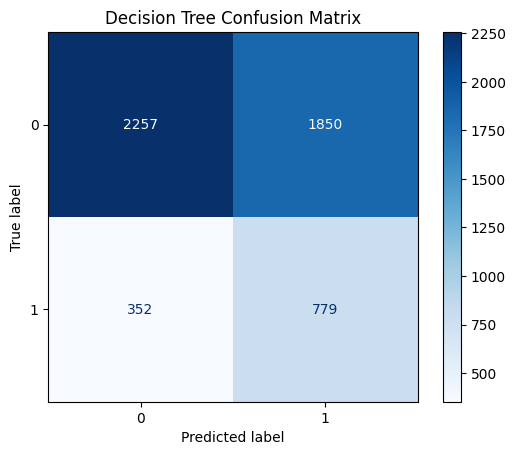

In [6]:
dt_y_pred = best_dt_model.predict(X_test)
print(classification_report(y_test, dt_y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, dt_y_pred)
fig, ax = plt.subplots()
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=best_dt_model.classes_
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Main analysis (random forest)

### Create a random forest model and tune hyperparameters

In [7]:
# Initialize random forest model
rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=123)

param_grid_rf = {
    "max_depth": [3, 5, 7, 10, 20, None],
    "n_estimators": [50, 100, 150],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"],
}

# Initialize GridSearchCV
rf_grid_search = GridSearchCV(
    rf,
    param_grid=param_grid_rf,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
rf_grid_search.fit(X_train, y_train)


print(
    f"We evaluated 6 maximum depth values, 3 tree counts, 3 minimum samples per split options, 3 minimum samples per leaf options, and 2 criteria across 5 cross-validation folds, totaling 810 experimental fits. Using recall as our metric, the best hyperparameters were {rf_grid_search.best_params_}, which achieved a score of {rf_grid_search.best_score_:.4f}."
)

We evaluated 6 maximum depth values, 3 tree counts, 3 minimum samples per split options, 3 minimum samples per leaf options, and 2 criteria across 5 cross-validation folds, totaling 810 experimental fits. Using recall as our metric, the best hyperparameters were {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 50}, which achieved a score of 0.6862.


### Display results

param_max_depth  param_n_estimators  param_min_samples_split  param_min_samples_leaf param_criterion  mean_test_accuracy  rank_test_accuracy  mean_test_precision  rank_test_precision  mean_test_recall  rank_test_recall  mean_test_f1  rank_test_f1
              3                  50                        2                       1            gini                0.60                 136                 0.30                  162              0.63               209          0.41           186
              3                 100                        2                       1            gini                0.59                 196                 0.30                  233              0.65               151          0.41           198
              3                 150                        2                       1            gini                0.59                 198                 0.30                  228              0.65               155          0.41           202
            

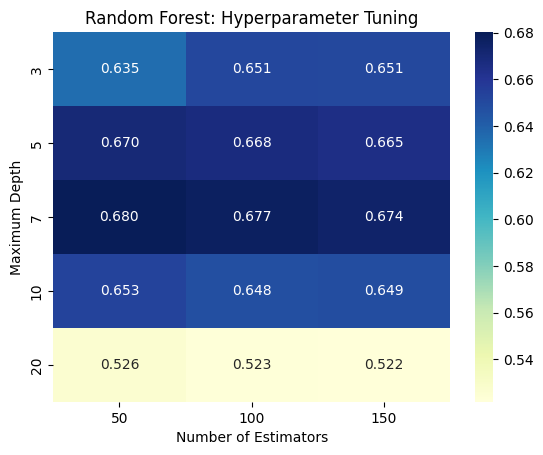

In [8]:
# Print results
rf_grid_search_results = pd.DataFrame(rf_grid_search.cv_results_)

rf_results_table = rf_grid_search_results[
    [
        "param_max_depth",
        "param_n_estimators",
        "param_min_samples_split",
        "param_min_samples_leaf",
        "param_criterion",
        "mean_test_accuracy",
        "rank_test_accuracy",
        "mean_test_precision",
        "rank_test_precision",
        "mean_test_recall",
        "rank_test_recall",
        "mean_test_f1",
        "rank_test_f1",
    ]
].copy()

print(rf_results_table.to_string(index=False, float_format="%.2f"))

# Plot results by hyperparameter
results_pivot = rf_grid_search_results.pivot_table(
    index="param_max_depth", columns="param_n_estimators", values="mean_test_recall"
)

plt.figure()
seaborn.heatmap(results_pivot, annot=True, cmap="YlGnBu", fmt=".3f")
plt.title("Random Forest: Hyperparameter Tuning")
plt.xlabel("Number of Estimators")
plt.ylabel("Maximum Depth")
plt.show()

### Interpret model

Using the tuned hyperparameters, the feature importance (based on impurity reduction) for each feature is:

STOP_WAS_INITIATED_based on self initiated                                 0.284320
SUSPECTED_CRIME_DESCRIPTION_cpw                                            0.176921
STOP_LOCATION_PATROL_BORO_NAME_pbms                                        0.101524
STOP_LOCATION_PATROL_BORO_NAME_pbbx                                        0.100432
SUSPECTED_CRIME_DESCRIPTION_assault                                        0.030466
STOP_WAS_INITIATED_based on c_w on scene                                   0.030229
SUSPECT_REPORTED_AGE_18–24                                                 0.029870
SUSPECTED_CRIME_DESCRIPTION_robbery                                        0.021397
SUSPECT_REPORTED_AGE_<18                                                   0.019713
SUSPECT_REPORTED_AGE_25–44                                                 0.017421
SUSPECTED_CRIME_DESCRIPTION_petit larceny           

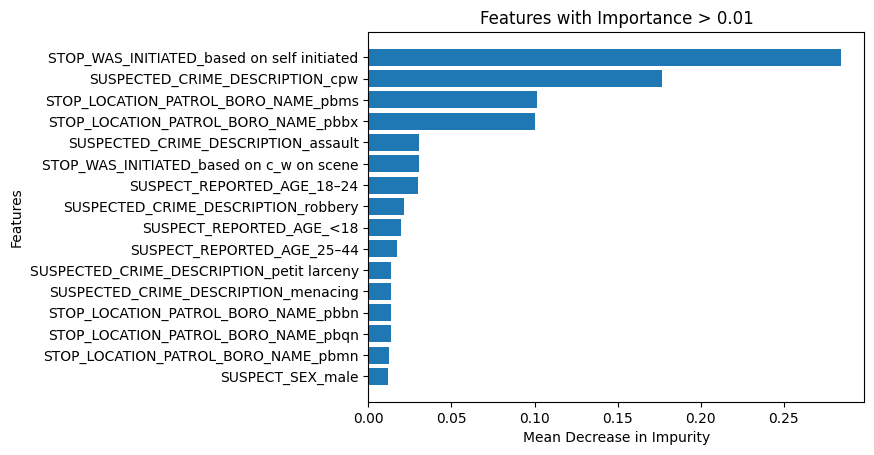

In [9]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_rf_model = rf_grid_search.best_estimator_

# Extract the feature importances from the best model
rf_importances = best_rf_model.feature_importances_
rf_feature_importances = pd.Series(rf_importances, index=X_train.columns)

print(
    "Using the tuned hyperparameters, the feature importance (based on impurity reduction) for each feature is:"
)
print()
print(rf_feature_importances.sort_values(ascending=False))

# Plot features that have values > 0.01
rf_plot_df = rf_feature_importances[rf_feature_importances > 0.01].sort_values(
    ascending=True
)

plt.figure()
plt.barh(rf_plot_df.index, rf_plot_df.values)
plt.title("Features with Importance > 0.01")
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Features")
plt.show()

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

           0       0.87      0.54      0.67      4107
           1       0.30      0.70      0.42      1131

    accuracy                           0.58      5238
   macro avg       0.58      0.62      0.54      5238
weighted avg       0.74      0.58      0.61      5238



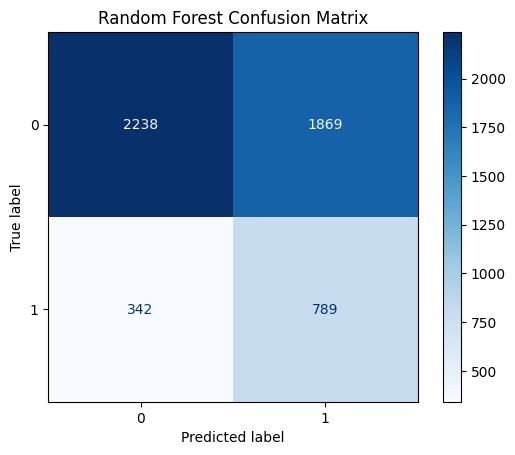

In [10]:
rf_y_pred = best_rf_model.predict(X_test)
print(classification_report(y_test, rf_y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, rf_y_pred)
fig, ax = plt.subplots()
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=best_rf_model.classes_
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Random Forest Confusion Matrix")
plt.show()

# Compare decision tree and random forest models

   Metric  Decision Tree  Random Forest
   Recall          0.689          0.698
Precision          0.296          0.297
 Accuracy          0.580          0.578
 F1-Score          0.414          0.416


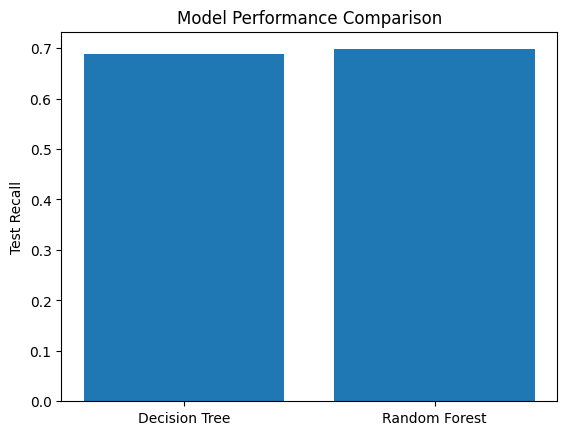

In [15]:
dt_y_pred = best_dt_model.predict(X_test)
rf_y_pred = best_rf_model.predict(X_test)

# Print out results for each of the models by the four metrics
results = {
    "Metric": ["Recall", "Precision", "Accuracy", "F1-Score"],
    "Decision Tree": [
        recall_score(y_test, dt_y_pred),
        precision_score(y_test, dt_y_pred),
        accuracy_score(y_test, dt_y_pred),
        f1_score(y_test, dt_y_pred),
    ],
    "Random Forest": [
        recall_score(y_test, rf_y_pred),
        precision_score(y_test, rf_y_pred),
        accuracy_score(y_test, rf_y_pred),
        f1_score(y_test, rf_y_pred),
    ],
}

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False, float_format="%.3f"))

# Plot recall results for the two models
fig, ax = plt.subplots()
bars = ax.bar(
    ["Decision Tree", "Random Forest"],
    [recall_score(y_test, dt_y_pred), recall_score(y_test, rf_y_pred)],
)
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Test Recall")
plt.show()